# Práctica 14. Filtrado de imágenes (Convolución)

<div class="alert alert-block alert-success">
<b>Resumen:</b> El código demuestra cómo aplicar filtros de convolución a una imagen en escala de grises utilizando Python y OpenCV, y cómo diferentes métodos de tratamiento de bordes afectan el resultado del filtrado.
</div>

***

### 1. Preámbulo

In [28]:
# Importar las bibliotecas
import cv2
import numpy as np
import matplotlib.pyplot as plt

### 2. Lectura de la imagen

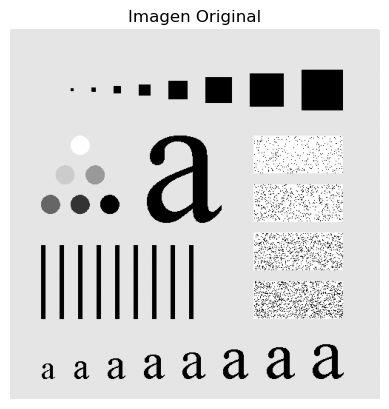

In [29]:
# Lectura y visualización de la imagen
im_gray_1 = cv2.imread(r'.\images\chessboard_calibration_setup.tif', cv2.IMREAD_GRAYSCALE)

# Mostrar la imagen original
plt.figure()
plt.imshow(im_gray_1, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')
plt.show()

### 3. Función `imfilter`( ... )

Máscara del filtro

In [30]:
# Definir el tamaño de la máscara (filtro)
w_size = 11
w = np.ones((w_size, w_size), dtype=np.float32) / (w_size * w_size)

<b>Actividad.</b> Consulte la ayuda de la función `filter2D` y conteste las siguientes preguntas.
- ¿Qué argumento controla la profundidad del resultado filtrado en la función `filter2D` y cuál es su propósito?
- ¿Cómo se define el tipo de bordes que se utilizará al aplicar la convolución en la función `filter2D`? ¿Qué opciones existen para este parámetro?
- ¿Qué sucede si el tamaño del núcleo (filtro) proporcionado a `filter2D` es par en alguna de sus dimensiones?

In [31]:
help(cv2.filter2D)

Help on built-in function filter2D:

filter2D(...)
    filter2D(src, ddepth, kernel[, dst[, anchor[, delta[, borderType]]]]) -> dst
    .   @brief Convolves an image with the kernel.
    .
    .   The function applies an arbitrary linear filter to an image. In-place operation is supported. When
    .   the aperture is partially outside the image, the function interpolates outlier pixel values
    .   according to the specified border mode.
    .
    .   The function does actually compute correlation, not the convolution:
    .
    .   \f[\texttt{dst} (x,y) =  \sum _{ \substack{0\leq x' < \texttt{kernel.cols}\\{0\leq y' < \texttt{kernel.rows}}}}  \texttt{kernel} (x',y')* \texttt{src} (x+x'- \texttt{anchor.x} ,y+y'- \texttt{anchor.y} )\f]
    .
    .   That is, the kernel is not mirrored around the anchor point. If you need a real convolution, flip
    .   the kernel using #flip and set the new anchor to `(kernel.cols - anchor.x - 1, kernel.rows -
    .   anchor.y - 1)`.
    .
    .   Th

In [32]:
# Filtrar la imagen con la máscara (filtro de convolución)
g_1 = cv2.filter2D(im_gray_1, -1, w, borderType=cv2.BORDER_REPLICATE)
g_2 = cv2.filter2D(im_gray_1, -1, np.rot90(w, 2), borderType=cv2.BORDER_REPLICATE)

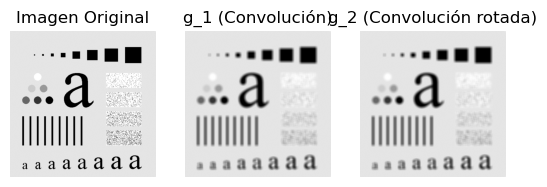

In [33]:
# Visualización de los resultados
plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(im_gray_1, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(g_1, cmap='gray')
plt.title('g_1 (Convolución)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(g_2, cmap='gray')
plt.title('g_2 (Convolución rotada)')
plt.axis('off')
plt.show()

### 4. Más opciones de filtrado de imágenes

In [34]:
g_3 = cv2.filter2D(im_gray_1, -1, w, borderType=cv2.BORDER_REPLICATE)
g_4 = cv2.filter2D(im_gray_1, -1, w, borderType=cv2.BORDER_REFLECT)

(np.float64(-0.5), np.float64(499.5), np.float64(499.5), np.float64(-0.5))

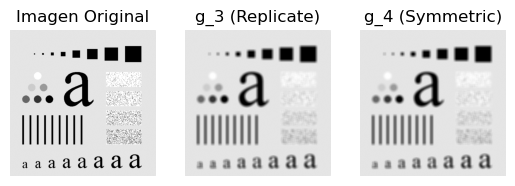

In [35]:
# Visualización de los resultados
plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(im_gray_1, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(g_3, cmap='gray')
plt.title('g_3 (Replicate)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(g_4, cmap='gray')
plt.title('g_4 (Symmetric)')
plt.axis('off')

***

<b>Actividad</b> Aplique un filtro promedio a la imagen `test_pattern_blurring_orig.tif`

In [36]:
# aquí su código